In [12]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import pickle
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd
from openTSNE import TSNE


env: CUDA_VISIBLE_DEVICES=1
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
dataset = "yao_10x"
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")

In [14]:
#to load the pkl file:
with open(os.path.join(res_path, "yao_10x_v2_pca50.pkl"), 'rb') as f:
     pkl_file= pickle.load(f)

pkl_file.keys() #output: dict_keys(['clusters', 'clusterColors', 'clusterNames', 'pca50'])


dict_keys(['clusters', 'clusterColors', 'clusterNames', 'pca50'])

In [15]:
meta = pd.read_csv(os.path.join(res_path, "10x_metadata.csv"))

In [16]:
print(meta.keys())

Index(['sample_name', 'donor_sex_id', 'donor_sex_label', 'donor_sex_color',
       'region_id', 'region_label', 'region_color', 'platform_label',
       'cluster_order', 'cluster_label', 'cluster_color', 'subclass_order',
       'subclass_label', 'subclass_color', 'neighborhood_id',
       'neighborhood_label', 'neighborhood_color', 'class_order',
       'class_label', 'class_color', 'exp_component_name',
       'external_donor_name_label', 'full_genotype_label',
       'facs_population_plan_label', 'injection_roi_label',
       'injection_materials_label', 'injection_method_label',
       'injection_type_label', 'full_genotype_id', 'full_genotype_color',
       'external_donor_name_id', 'external_donor_name_color',
       'facs_population_plan_id', 'facs_population_plan_color',
       'injection_materials_id', 'injection_materials_color',
       'injection_method_id', 'injection_method_color', 'injection_roi_id',
       'injection_roi_color', 'injection_type_id', 'injection_type_color

In [5]:
meta["donor_sex_label"].values[:20]

array(['M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M',
       'F', 'M', 'M', 'M', 'M', 'M', 'M'], dtype=object)

In [6]:
pkl_file['pca50'].shape

(1169213, 50)

In [7]:
pkl_file['clusters'][:10]

array([115, 363,  17,  14,  17,  17,  17,  14,  17,  17])

In [8]:
pkl_file['clusterNames'][pkl_file['clusters'][:10]]

array(['116_Pvalb', '364_DG', '18_Lamp5', '15_Lamp5', '18_Lamp5',
       '18_Lamp5', '18_Lamp5', '15_Lamp5', '18_Lamp5', '18_Lamp5'],
      dtype='<U23')

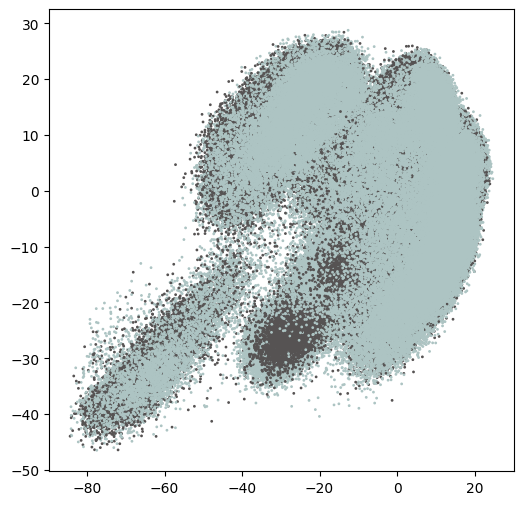

In [9]:
fig, ax = plt.subplots(figsize=(6,6))

#ax.scatter(*pkl_file['pca50'][:, :2].T, s=1, c=pkl_file['clusterColors'][pkl_file['clusters']])
ax.scatter(*pkl_file['pca50'][:, :2].T, s=1, c=meta["donor_sex_color"])

In [5]:
def load_dict(filename_):
    with open(filename_, 'rb') as f:
        ret_di = pickle.load(f)
    return ret_di

In [11]:
k = 15
n_epochs = 500
n_early_epochs = 250
perplexity = None
rescale_tsne = True
seed = 0

file_name = os.path.join(res_path,
                         f"tsne_bin_k_{k}_n_epochs_{n_epochs}_n_early_epochs_{n_early_epochs}_seed_{seed}_init_pca_rescale_{rescale_tsne}.pkl")

tsne_data = load_dict(file_name)
embd = tsne_data["embds"][-1]

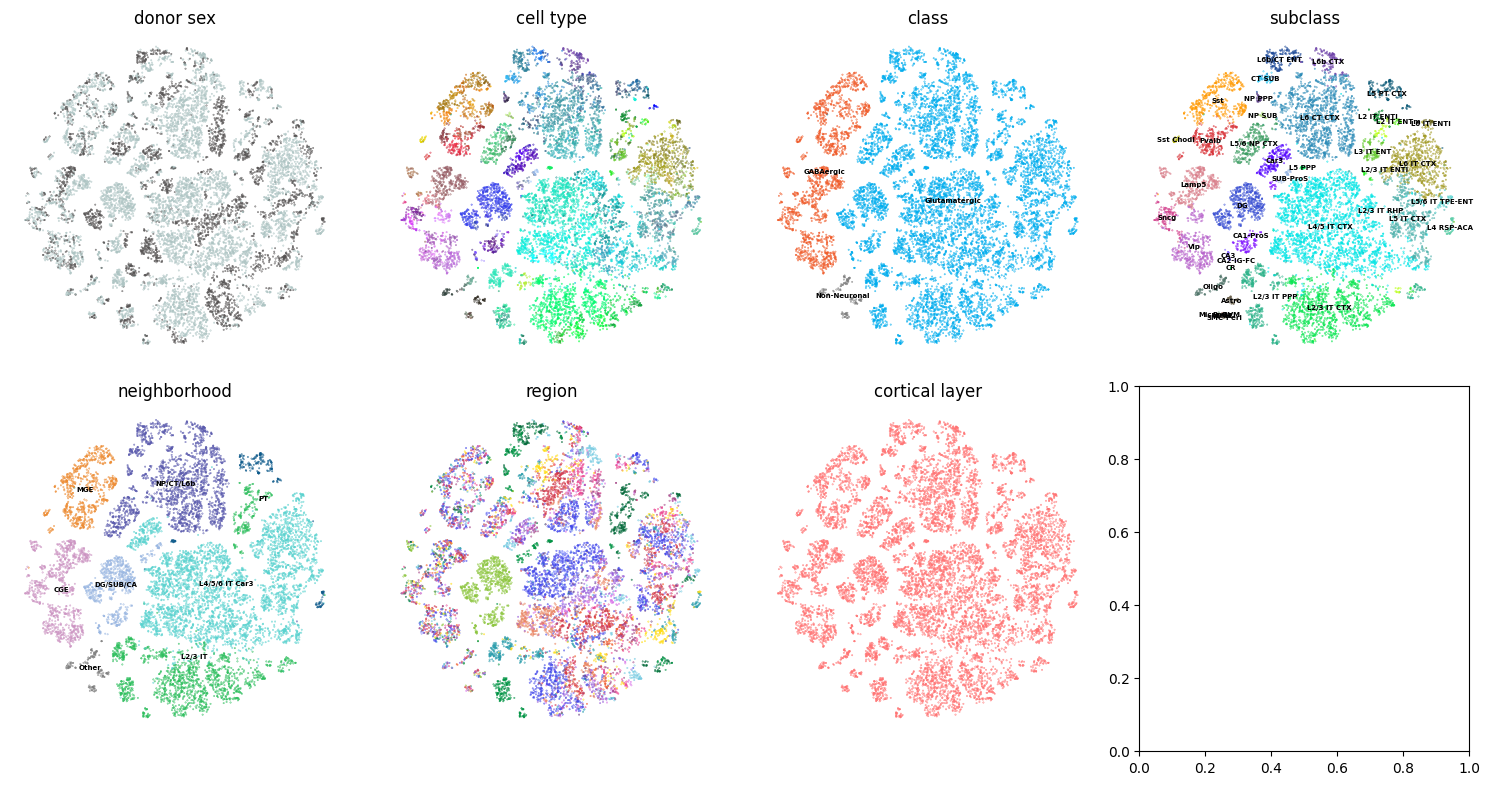

In [30]:
n_plot = 10000  # set to None to plot all points

rng = np.random.default_rng(0)
if n_plot is not None and n_plot < len(embd):
    plot_idx = rng.choice(len(embd), size=n_plot, replace=False)
else:
    plot_idx = np.arange(len(embd))

embd_plot = embd[plot_idx]
meta_plot = meta.iloc[plot_idx].reset_index(drop=True)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))

panels = [
    ("donor_sex_color",      "donor sex",      None),
    ("cluster_color",        "cell type",      None),
    ("class_color",          "class",          "class_label"),
    ("subclass_color",       "subclass",       "subclass_label"),
    ("neighborhood_color",   "neighborhood",   "neighborhood_label"),
    ("region_color",         "region",         None),
    ("cortical_layer_color", "cortical layer", None),
]

embd_df = pd.DataFrame({"x": embd_plot[:, 0], "y": embd_plot[:, 1]})

for ax, (col, title, label_col) in zip(axes.flatten(), panels):
    ax.scatter(*embd_plot.T, s=0.1, c=meta_plot[col], alpha=1)
    ax.set_title(title)
    ax.axis("off")
    ax.set_aspect("equal")

    if label_col is not None:
        means = embd_df.assign(label=meta_plot[label_col].values).groupby("label")[["x", "y"]].mean()
        for lbl, row in means.iterrows():
            ax.text(row["x"], row["y"], lbl, fontsize=5, ha="center", va="center", fontweight="bold")

fig.tight_layout()

In [72]:
# Look for subclasses that are separated by sex, but have stable sex ratio per cluster

In [73]:
from sklearn.neighbors import NearestNeighbors


def sex_knn_score(pca, sex_labels, k=15, n_sample=3000, seed=42):
    """
    Normalised kNN same-sex fraction.
    0 = random mixing, 1 = perfect M/F separation (strong batch effect).
    """
    rng = np.random.default_rng(seed)
    if len(pca) > n_sample:
        idx = rng.choice(len(pca), n_sample, replace=False)
        pca, sex_labels = pca[idx], sex_labels[idx]
    nn = NearestNeighbors(n_neighbors=k + 1).fit(pca)
    _, nbrs = nn.kneighbors(pca)
    obs = (sex_labels[nbrs[:, 1:]] == sex_labels[:, None]).mean()
    f = (sex_labels == "F").mean()
    expected = f ** 2 + (1 - f) ** 2  # random baseline given class imbalance
    return float((obs - expected) / (1 - expected))


def sex_ratio_std(meta_sub):
    """Std of per-cluster female fraction. Low = stable sex ratios across clusters."""
    ratios = (meta_sub.groupby("cluster_label")["donor_sex_label"]
              .apply(lambda x: (x == "F").mean()))
    return float(ratios.std())


records = []
for level, col in [("subclass", "subclass_label"),
                   ("neighborhood", "neighborhood_label"),
                   ("class", "class_label")]:
    for group in meta[col].unique():
        mask = (meta[col] == group).values
        n_cells = int(mask.sum())
        meta_sub = meta[mask].reset_index(drop=True)
        n_clusters = meta_sub["cluster_label"].nunique()
        if not (1 <= n_clusters <= 20) or n_cells > 21_000:
            continue
        pca_sub = pkl_file["pca50"][mask]
        sex_sub = meta_sub["donor_sex_label"].values
        records.append({
            "level": level,
            "group": group,
            "n_cells": n_cells,
            "n_clusters": n_clusters,
            "sex_knn_score": sex_knn_score(pca_sub, sex_sub),
            "sex_ratio_std": sex_ratio_std(meta_sub),
        })

df_scan = (pd.DataFrame(records)
           .sort_values("sex_knn_score", ascending=False)
           .reset_index(drop=True))
print(df_scan.to_string())

       level            group  n_cells  n_clusters  sex_knn_score  sex_ratio_std
0   subclass       L4 RSP-ACA     4593           2       0.945243       0.487368
1   subclass        L3 IT ENT    13362           6       0.849257       0.057279
2   subclass       L2 IT ENTl     4568           1       0.767370            NaN
3   subclass            Astro     3899           3       0.764312       0.038473
4   subclass     L2/3 IT ENTl     6433          10       0.756967       0.160532
5   subclass       L2 IT ENTm     2225           5       0.751364       0.149678
6   subclass         CA1-ProS    15897          20       0.742047       0.250642
7   subclass      L2/3 IT RHP     3096           6       0.734972       0.059170
8   subclass              CA3     1675          10       0.697484       0.189334
9   subclass         SUB-ProS     4187          11       0.694492       0.187801
10  subclass           NP PPP     2612           3       0.690235       0.128494
11  subclass       L6b/CT EN

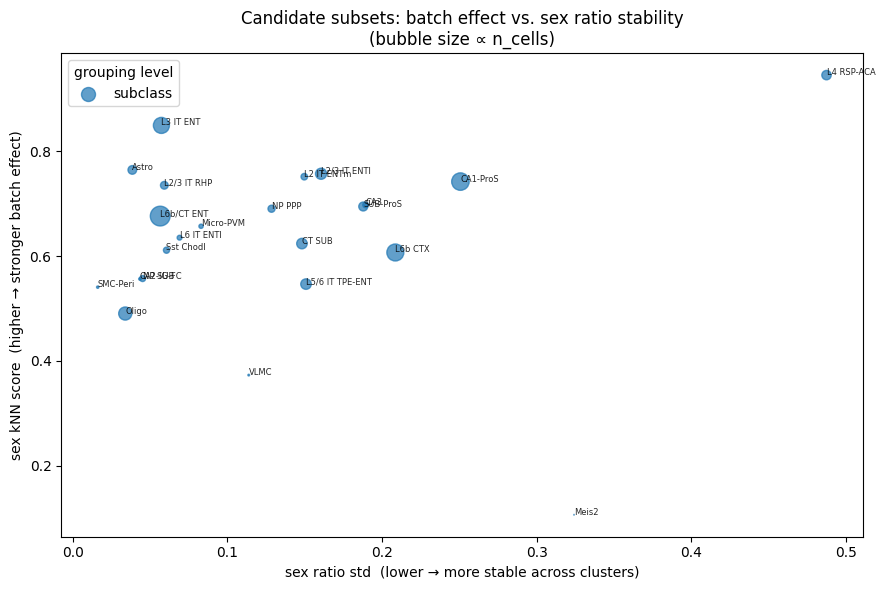

In [74]:
fig, ax = plt.subplots(figsize=(9, 6))

markers = {"subclass": "o", "neighborhood": "s", "class": "^"}
for level, grp in df_scan.groupby("level"):
    sc = ax.scatter(grp["sex_ratio_std"], grp["sex_knn_score"],
                    s=grp["n_cells"] / 100, alpha=0.7,
                    marker=markers[level], label=level)
    for _, row in grp.iterrows():
        ax.annotate(row["group"],
                    (row["sex_ratio_std"], row["sex_knn_score"]),
                    fontsize=6, alpha=0.85)

ax.set_xlabel("sex ratio std  (lower → more stable across clusters)")
ax.set_ylabel("sex kNN score  (higher → stronger batch effect)")
ax.legend(title="grouping level")
ax.set_title("Candidate subsets: batch effect vs. sex ratio stability\n(bubble size ∝ n_cells)")
fig.tight_layout()

In [75]:
# --> seems like L2/3 ENT subclasses would work well. Select those below:

In [77]:
mask_L23_ent = meta["subclass_label"].isin(["L2 IT ENTl", "L2 IT ENTm", "L3 IT ENT", "L2/3 IT ENTl"]).values
meta_L23_ent = meta[mask_L23_ent].reset_index(drop=True)

In [ ]:

embd_L23_ent = embd[mask_L23_ent]

print(f"{mask_L23_ent.sum()} cells selected")

In [7]:
# unique color per cluster (reused by the tSNE scatter cell below)
unique_clusters = sorted(meta_L23_ent["cluster_label"].unique())
cmap = plt.get_cmap("tab20", len(unique_clusters))
cluster_color_map = {cl: cmap(i) for i, cl in enumerate(unique_clusters)}

In [ ]:
# ── figure layout: 2 scatter + 2 bar plots ───────────────────────────────────
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, hspace=0.4, wspace=0.35)

ax_ct  = fig.add_subplot(gs[0, 0])
ax_sex = fig.add_subplot(gs[0, 1])
ax_bar_ct  = fig.add_subplot(gs[1, 0])
ax_bar_sex = fig.add_subplot(gs[1, 1])

# ── scatter panels ────────────────────────────────────────────────────────────
cell_colors_L23_ent = meta_L23_ent["cluster_label"].map(cluster_color_map).tolist()

ax_ct.scatter(*embd_L23_ent.T, s=1, c=cell_colors_L23_ent, alpha=0.4)
ax_ct.set_title("cell type")
ax_ct.axis("off")
ax_ct.set_aspect("equal")

ax_sex.scatter(*embd_L23_ent.T, s=1, c=meta_L23_ent["donor_sex_color"], alpha=0.4)
ax_sex.set_title("donor sex")
ax_sex.axis("off")
ax_sex.set_aspect("equal")


# ── bar: total counts per cell type ──────────────────────────────────────────
ct_counts = meta_L23_ent["cluster_label"].value_counts().sort_index()
bar_colors = [cluster_color_map[cl] for cl in ct_counts.index]

ax_bar_ct.bar(range(len(ct_counts)), ct_counts.values, color=bar_colors)
ax_bar_ct.set_xticks(range(len(ct_counts)))
ax_bar_ct.set_xticklabels(ct_counts.index, rotation=90, fontsize=6)
ax_bar_ct.set_ylabel("# cells")
ax_bar_ct.set_title("Cell count per cluster")

# ── bar: sex breakdown per cell type (stacked) ────────────────────────────────
sex_ct = (meta_L23_ent.groupby(["cluster_label", "donor_sex_label"])
                 .size()
                 .unstack(fill_value=0)
                 .reindex(ct_counts.index))

sex_colors = (meta_L23_ent.drop_duplicates("donor_sex_label")
                      .set_index("donor_sex_label")["donor_sex_color"]
                      .to_dict())

bottom = np.zeros(len(sex_ct))
for sex in sex_ct.columns:
    ax_bar_sex.bar(range(len(sex_ct)), sex_ct[sex].values,
                   bottom=bottom, label=sex, color=sex_colors.get(sex, None))
    bottom += sex_ct[sex].values

ax_bar_sex.set_xticks(range(len(sex_ct)))
ax_bar_sex.set_xticklabels(sex_ct.index, rotation=90, fontsize=6)
ax_bar_sex.set_ylabel("# cells")
ax_bar_sex.set_title("Sex breakdown per cluster (stacked)")
ax_bar_sex.legend(title="sex", fontsize=8)

fig.suptitle(f"L2/L3 IT ENT  (n={mask_L23_ent.sum():,})", fontsize=13)
plt.show()

In [17]:
mask_ent = meta["subclass_label"].isin(["L2 IT ENTl", "L2 IT ENTm", "L3 IT ENT", "L2/3 IT ENTl"]).values
meta_ent = meta[mask_ent].reset_index(drop=True)
cell_colors = meta_ent["cluster_label"].map(cluster_color_map).tolist()

pca_ent  = pkl_file["pca50"][mask_ent]

print(f"{mask_ent.sum()} cells — running tSNE on PCA50...")

26588 cells — running tSNE on PCA50...


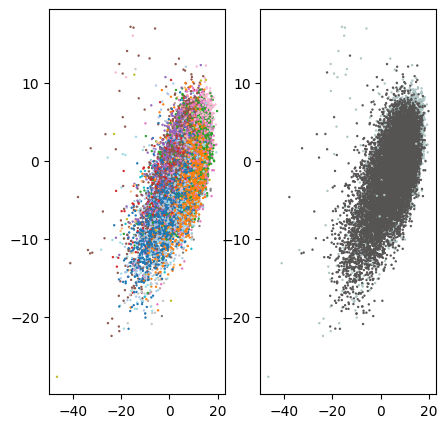

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(5,5))

ax[0].scatter(*pca_ent[:, :2].T, c=cell_colors, s=0.5)
ax[1].scatter(*pca_ent[:, :2].T, c=meta_ent["donor_sex_color"], s=0.5)

# PCA has very good batch integrationl, but poor cluster separation

In [67]:
embedder_ent = TSNE(verbose=True)
embd_ent = embedder_ent.fit(pca_ent)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
Iteration  450, KL divergence 2.9851, 50 iterations in 7.8725 sec
Iteration  500, KL divergence 2.9750, 50 iterations in 7.8979 sec
   --> Time elapsed: 51.60 seconds


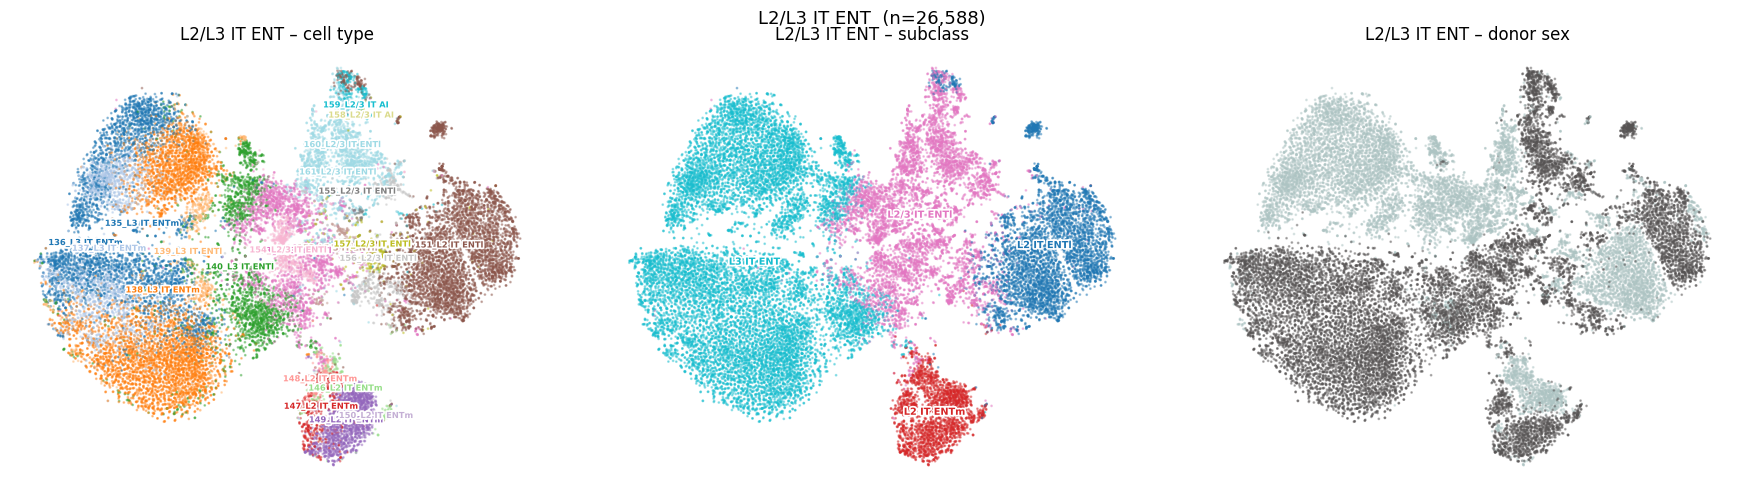

In [70]:
import matplotlib.patheffects as pe

cell_colors = meta_ent["cluster_label"].map(cluster_color_map).tolist()

# unique color per subclass
unique_subclasses = sorted(meta_ent["subclass_label"].unique())
cmap_sub = plt.get_cmap("tab10", len(unique_subclasses))
subclass_color_map = {sc: cmap_sub(i) for i, sc in enumerate(unique_subclasses)}
subclass_colors = meta_ent["subclass_label"].map(subclass_color_map).tolist()

stroke = [pe.withStroke(linewidth=2.5, foreground="white")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(*embd_ent.T, s=1, c=cell_colors, alpha=0.4)
axes[0].set_title("L2/L3 IT ENT – cell type")
axes[0].axis("off")
axes[0].set_aspect("equal")

axes[1].scatter(*embd_ent.T, s=1, c=subclass_colors, alpha=0.4)
axes[1].set_title("L2/L3 IT ENT – subclass")
axes[1].axis("off")
axes[1].set_aspect("equal")

axes[2].scatter(*embd_ent.T, s=1, c=meta_ent["donor_sex_color"], alpha=0.4)
axes[2].set_title("L2/L3 IT ENT – donor sex")
axes[2].axis("off")
axes[2].set_aspect("equal")

# cluster name labels at mean positions
ct_df = pd.DataFrame({"x": embd_ent[:, 0], "y": embd_ent[:, 1], "label": meta_ent["cluster_label"]})
for lbl, row in ct_df.groupby("label")[["x", "y"]].mean().iterrows():
    axes[0].text(row["x"], row["y"], lbl, fontsize=6, ha="center", va="center",
                 fontweight="bold", color=cluster_color_map[lbl], path_effects=stroke)

# subclass name labels at mean positions
sc_df = pd.DataFrame({"x": embd_ent[:, 0], "y": embd_ent[:, 1], "label": meta_ent["subclass_label"]})
for lbl, row in sc_df.groupby("label")[["x", "y"]].mean().iterrows():
    axes[1].text(row["x"], row["y"], lbl, fontsize=7, ha="center", va="center",
                 fontweight="bold", color=subclass_color_map[lbl], path_effects=stroke)

fig.suptitle(f"L2/L3 IT ENT  (n={mask_ent.sum():,})", fontsize=13)
fig.tight_layout()

# decent cluster purity in t-SNE, but no batch integration. Jointly the selected subclasses make sense (ENT cells going from L2l / m via L2/L3 to L3

In [78]:
import matplotlib.colors as mcolors

save_path = ("/gpfs01/berens/user/sdamrich/data/ne_aligned/yao_10x_ent_l2l3")

# PCA50
np.save(os.path.join(save_path, "ent_l2l3_pca50.npy"), pca_ent)

# metadata: all existing columns + new tab20/tab10 color columns
meta_save = meta_ent.copy()
meta_save["cluster_color_new"] = meta_ent["cluster_label"].map(
    {cl: mcolors.to_hex(c) for cl, c in cluster_color_map.items()}
)
meta_save["subclass_color_new"] = meta_ent["subclass_label"].map(
    {sc: mcolors.to_hex(c) for sc, c in subclass_color_map.items()}
)
meta_save.to_csv(os.path.join(save_path, "ent_l2l3_meta.csv"), index=False)

print(f"Saved pca50:    ent_l2l3_pca50.npy   {pca_ent.shape}")
print(f"Saved metadata: ent_l2l3_meta.csv     {meta_save.shape}")

Saved pca50:    ent_l2l3_pca50.npy   (26588, 50)
Saved metadata: ent_l2l3_meta.csv     (26588, 59)


In [ ]:
#counts_ent, genes_ent = ex tract_ent_l2l3_counts(res_path, save_path, mask_ent)

In [29]:
import time
from vis_utils.rnaseqTools import geneSelection
from vis_utils.utils import save_dict
import scipy.sparse as sparse
import random

[KeOps] Compiling cuda jit compiler engine ... OK
[pyKeOps] Compiling nvrtc binder for python ... OK


In [23]:
def find_mutual_genes(data_dir):
    file_10x = os.path.join(data_dir, "10x_matrix.csv")
    file_smart = os.path.join(data_dir, "smart-seq_matrix.csv")

    gene_smart = pd.read_csv(file_smart, nrows = 0).columns.tolist()
    gene_10x = pd.read_csv(file_10x, nrows = 0).columns.tolist()
    sane_columns = []
    for col in gene_10x:
        if col in gene_smart:
            sane_columns.append(col)

    np.save(os.path.join(data_dir, "mutual_genes.txt"), sane_columns)

    return sane_columns

In [88]:
def sparseload_sample(
    filename,
    usecols,
    skiprows = None,
    s=None,
    sep=",",
    dtype=float,
    chunksize=10000,
    names=None,
    index_col=0,
    droplastcolumns=0,
    seed = 0,
):
    genes = []
    sparseblocks = []

    if s is not None:
        random.seed(seed)
        n = 1169320
        skip = sorted(random.sample(range(1,n),n-s))
    else:
        skip = skiprows

    for i, chunk in enumerate(
        pd.read_csv(
            filename, usecols=usecols, skiprows=skip, chunksize=chunksize, sep=sep, names=names, index_col=index_col        )
    ):
        print(".", end="", flush=True)
        if i%100 == 0:
            current_time = time.strftime("%H:%M:%S", time.localtime())
            print(f"{i} chunk is done. Time: {current_time}")
        genes.extend(list(chunk.index))
        if i == 0:
            cells = np.array(chunk.columns)
        sparseblock = sparse.csr_matrix(chunk.values.astype(dtype))
        # print(sparseblock.shape)
        sparseblocks.append([sparseblock])

    counts = sparse.bmat(sparseblocks)
    print(" done")

    if droplastcolumns > 0:
        end = cells.size - droplastcolumns
        cells = cells[:end]
        counts = counts[:, :end]

    return (counts, cells, np.array(genes)) # but actually here genes = cells, cells = np.array(genes)


def sparseload(
    filename,
    usecols=None,
    row_positions=None,   # <-- desired data-row positions
    sep=",",
    dtype=float,
    chunksize=10000,
    names=None,
    index_col=0,
    droplastcolumns=0,
    yao=False,
):

    skiprows = None
    if row_positions is not None:
        n_rows = 1169320 # full number of rows in 10x_matrix.csv

        row_positions = np.asarray(row_positions)
        keep = set(row_positions)

        # pandas skiprows uses CSV line numbers.
        # If names is None, line 0 is the header, so data row k is line k+1.
        if names is None:
            skiprows = [i + 1 for i in range(n_rows) if i not in keep]
        else:
            # no header assumed
            skiprows = [i for i in range(n_rows) if i not in keep]

    genes = []
    sparseblocks = []
    for i, chunk in enumerate(
        pd.read_csv(
            filename, usecols = usecols, chunksize=chunksize, sep=sep, names=names, index_col=index_col,            skiprows=skiprows,
        )
    ):
        print(".", end="", flush=True)
        print(chunk.columns)
        genes.extend(list(chunk.index))
        if i == 0:
            cells = np.array(chunk.columns)
        sparseblock = sparse.csr_matrix(chunk.values.astype(dtype))
        print(sparseblock.shape)
        sparseblocks.append([sparseblock])

    counts = sparse.bmat(sparseblocks)
    print(" done")

    if droplastcolumns > 0:
        end = cells.size - droplastcolumns
        cells = cells[:end]
        counts = counts[:, :end]

    if yao == False:
        return (counts.T, np.array(genes), cells)
    else:
        return (counts, cells, np.array(genes)) # but actually here genes = cells, cells = np.array(genes)


In [31]:
data_dir = "/gpfs01/berens/data/sharing_files/sdamrich/eff-ph/data/yao"
result_dir = res_path

In [32]:
mutual_gene = os.path.join(data_dir, "mutual_genes.npy")
if not os.path.exists(mutual_gene):
    sane_columns = find_mutual_genes(data_dir)
else:
    sane_columns = np.load(mutual_gene)
    print("loading mutual genes...")


loading mutual genes...


In [33]:
sane_columns

array(['sample_name', 'Xkr4', 'Rp1', ..., 'Gm6020', 'Csf2ra', 'Gm13298'],
      shape=(24141,), dtype='<U16')

In [52]:
##### 2: GET counts
print("Preprocessing")
file_name_10x = os.path.join(data_dir, "10x_matrix.csv")
# file_name_10x_try = os.path.join(data_dir, "10x_matrix_10k.csv")
start_load_time = time.time()
# load only a subsample, to get an estimate of the important genes. Then load those for all cells.
counts, genes, cells = sparseload_sample(file_name_10x, sane_columns, s = 50000, chunksize = 2500)
current_time = time.strftime("%H:%M:%S", time.localtime())
end_load_time = time.time()
print(f"counts are done. Time: {current_time}")
print(f"Duration: {end_load_time - start_load_time}")
print(counts.shape)

Preprocessing
.0 chunk is done. Time: 11:30:22
................... done
counts are done. Time: 11:38:34
Duration: 518.5252301692963
(50000, 24140)


Chosen offset: 0.00
['Xkr4' 'Sntg1' '3110035E14Rik' 'A830018L16Rik' 'Kcnb2' 'Kcnq5' 'Rims1'
 'Ogfrl1' 'Col19a1' 'Khdrbs2' 'Tmeff2' 'Map2' 'Erbb4' 'Igfbp5' 'Epha4'
 'Nyap2' 'Dner' 'Fbxo36' 'Kif1a' 'Pam' 'Cntnap5b' 'Cntnap5a' 'Ptpn4'
 'Dpp10' 'Lypd1' 'R3hdm1' 'Thsd7b' 'Nfasc' 'Brinp3' 'Tnr' 'Atp1b1' 'Pbx1'
 'Rgs4' 'Nos1ap' 'Rgs7' 'Kcnk2' 'Frmd4a' 'Celf2' 'C1ql3' 'Cacnb2' 'Etl4'
 'Gpr158' 'Gad2' 'Olfm1' 'Ntng2' 'Dnm1' '1110008P14Rik' 'Stxbp1' 'Garnl3'
 'Strbp' 'Lrp1b' 'Zeb2' 'Cacnb4' 'Nr4a2' 'Kcnh7' 'Gad1' 'Hat1' 'Dlx1as'
 'Chn1' 'Pde1a' 'Zfp804a' 'Trp53i11' 'Lrrc4c' 'Slc1a2' 'D430041D05Rik'
 'Mettl15' 'Bdnf' 'Ano3' 'Ryr3' 'Meis2' 'Rasgrp1' 'Serf2' 'Frmd5' 'Sema6d'
 'Mal' 'Pdyn' 'Plcb1' 'Snap25' 'Macrod2' 'Pcsk2' 'Slc24a3' 'Napb' 'Cst3'
 'Fkbp1a' 'Map1lc3a' '2900097C17Rik' 'Nnat' 'Snhg11' 'Ptprt' 'Ywhab'
 'Tshz2' 'Gnas' 'Stmn3' 'Syp' 'Pcsk1n' 'Tspan7' 'Syn1' 'Cul4b' 'Gria3'
 'Tenm1' 'Fgf13' 'Dmd' 'Il1rapl1' 'Xist' 'Plp1' 'Il1rapl2' 'Cnksr2'
 'Gpm6b' 'Tmsb4x' 'Frmpd4' 'Stmn2' 'Ralyl' 'Crh'

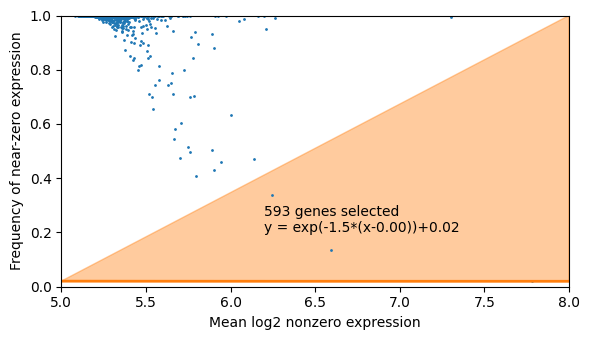

In [54]:
importantGenesYao = geneSelection(
    counts, n=3000, threshold=32)

sampled_columns = np.array(sane_columns[1:])[importantGenesYao.tolist()]
print(sampled_columns)
current_time = time.strftime("%H:%M:%S", time.localtime())
print(f"selecting genes are done. Time: {current_time}")

# counts_full, genes_full, cells_full = sparseload_sample(file_name_10x, sampled_columns, s = 500000, chunksize = 10000, index_col=None)

In [55]:
importantGenesYao.sum()

np.int64(593)

In [56]:
# onl

In [57]:
from itertools import combinations
sampled_columns_old = np.array(sane_columns[1:])[importantGenesYao_old.tolist()]

selected_sets = [set(sampled_columns), set(sampled_columns_old)]
for i, j in combinations(range(len(selected_sets)), 2):
    a = selected_sets[i]
    b = selected_sets[j]
    jaccard = len(a & b) / len(a | b)
    overlap = len(a & b) / min(len(a), len(b))

    print(i, j, "Jaccard:", jaccard, "Overlap:", overlap)

0 1 Jaccard: 1.0 Overlap: 1.0


In [ ]:
importantGenesYao_old = importantGenesYao.copy()


In [58]:
# save importantGenesYao
np.save(os.path.join(res_path, "selected_genes.npy"), sampled_columns)
np.save(os.path.join(res_path, "selected_genes_mask.npy"), importantGenesYao)

In [110]:
start_full_load_time = time.time()
counts_full, genes_full, cells_full = sparseload(file_name_10x,
                                                 #[0,1],
                                                 np.concatenate([["sample_name"],sampled_columns]),
                                                 chunksize = 250000,
                                                 yao = True)  #1169320
# np.save(os.path.join(result_dir, "counts_full.npy"), counts_full)
# actually its quite good, tho only 367 genes are selected....... and 10 minutes in total.....
end_full_load_time = time.time()
print(f"counts are done. Time: {end_full_load_time - start_full_load_time}")
current_time = time.strftime("%H:%M:%S", time.localtime())

#what = {'counts': counts_full, 'genes': genes_full, 'cells_full': cells_full}
#save_dict(what, os.path.join(result_dir, "what.pkl"))

print(f"Preprocessing is done. Time: {current_time}")

.Index(['Xkr4'], dtype='object')
(250000, 1)
.Index(['Xkr4'], dtype='object')
(250000, 1)
.Index(['Xkr4'], dtype='object')
(250000, 1)
.Index(['Xkr4'], dtype='object')
(250000, 1)
.Index(['Xkr4'], dtype='object')
(169320, 1)
 done
counts are done. Time: 343.0985128879547
Preprocessing is done. Time: 13:40:53


In [61]:
counts_full.shape

(1169320, 593)

In [65]:
cells_full.shape

(1169320,)

In [66]:
type(cells_full)

numpy.ndarray

In [63]:
##### 4: GET cluster, clusterNames, clusterColors
print("Getting cluster thingy")

clusterInfo = pd.read_csv(os.path.join(data_dir, "10x_metadata.csv"),
                                usecols=['sample_name', 'cluster_order',"cluster_label", "cluster_color"])
print("loaded metadata")

Getting cluster thingy
loaded metadata


In [64]:
goodCells = clusterInfo['sample_name'].values
ids = clusterInfo['cluster_order'].values #in tasic was "cluster_id"
labels = clusterInfo['cluster_label'].values
colors = clusterInfo['cluster_color'].values
clusterNames = np.array([labels[ids == i + 1][0] for i in range(np.max(ids)) if len(labels[ids == i + 1])>0])
clusterColors = np.array([colors[ids == i + 1][0] for i in range(np.max(ids)) if len(colors[ids == i + 1])>0])
print("prepared cluster names and colors")

prepared cluster names and colors


In [68]:
goodCells.shape

(1169213,)

In [69]:
unique_sorted = sorted(set(ids))
value_map = {value: idx for idx, value in enumerate(unique_sorted)}

# the code below has complexity len(cells_full) * len(goodCells)
#ind = np.array([np.where(cells_full == c)[0][0] for c in goodCells if len(np.where(cells_full == c)[0])>0])

# this alternative has complexity len(cells_full) + len(goodCells)
pos = {cell: i for i, cell in enumerate(cells_full)}
ind = np.array([pos[c] for c in goodCells if c in pos])
print(ind[:100])

counts_filtered = counts_full[ind, :]
cells_filtered = cells_full[ind]
clusters = np.array([value_map[num] for num in ids])

np.save(os.path.join(result_dir, "labels_new.npy"), clusters)

current_time = time.strftime("%H:%M:%S", time.localtime())
print(f"Getting cluster things is done. Time: {current_time}")

yao = {'counts': counts_filtered, 'genes': cells_filtered,'clusters': clusters,
            'clusterColors': clusterColors, 'clusterNames': clusterNames}

print(counts_full.shape)
save_dict(yao, os.path.join(result_dir, "yao_new.pkl"))

current_time = time.strftime("%H:%M:%S", time.localtime())
print(f"Saving pkl thingy is done. Time: {current_time}")

[ 691956  694184 1155343 1155943 1158617 1160276 1162207 1138771 1139362
 1141041 1124910 1129516 1109841 1166808     805    2730    4201    5260
    5674    6179   13684   14717   16122   18484   23183   31811   31991
   32388   33925   36219   36430   41849   42826   49343   52560   57145
   61870   79715   83354   89569   91880   94085   95953   96673   99425
  100072  101996  112300  120726  121221  126208  128224  134874  137707
  142619  144013  152721  159900  162009  164443  170633  172566  172654
  180231  186603  195299  197072  199175  199194  205786  207573  214753
  216075  222160  226254  228412  229055  243199  256428  265369  270258
  277761  280294  288319  374063  382511  385449  387941  388194  393671
  393995  404006  404189  405592  413954  414838  417367  424705  429702
  435706]
Getting cluster things is done. Time: 12:26:41
(1169213, 593)
Saving pkl thingy is done. Time: 12:26:48


In [73]:
print(yao["counts"].shape)

(1169213, 593)


In [75]:
# yao = load_dict(os.path.join(result_dir, "yao.pkl"))

librarySizes = np.sum(yao['counts'], axis=1)
# [:, importantGenesYao]
X = np.log1p(yao['counts'] / librarySizes * 1e+6) # / np.log(2)  # is supposed to be log_2 (1+x)
print(X.shape)
X = X.toarray()
print(X.shape)
# X_mean = X.mean(axis=0)
# X = X - X_mean
U, s, V = np.linalg.svd(X-X.mean(axis=0), full_matrices=False)

U[:, np.sum(V, axis=1) < 0] *= -1
X = np.dot(U, np.diag(s))
x = X[:, np.argsort(s)[::-1]][:, :50]

# #larger data.....
# # largedata = (cell_number, 3000)
# largedata = largedata - X_mean
# large_X = np.dot(largedata, V)[:, np.argsort(s)[::-1]] #????
# #larger data.....

d = yao
y = yao["clusters"]

(1169213, 593)
(1169213, 593)


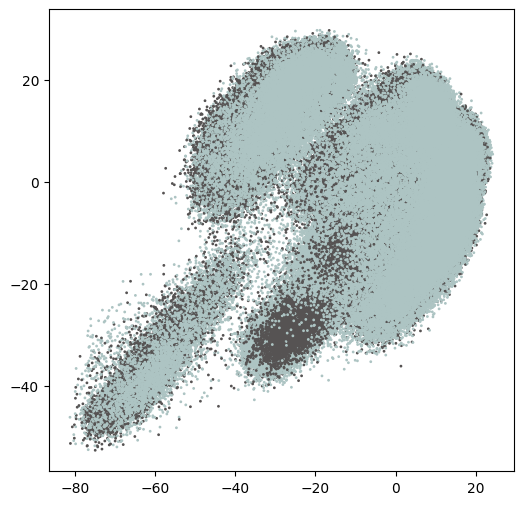

In [76]:
fig, ax = plt.subplots(figsize=(6,6))

#ax.scatter(*pkl_file['pca50'][:, :2].T, s=1, c=pkl_file['clusterColors'][pkl_file['clusters']])
ax.scatter(*x[:, :2].T, s=1, c=meta["donor_sex_color"])

In [ ]:
# subset after gene selection


In [78]:
# tsne of new full PCA
embedder_ent = TSNE(verbose=True)
embd_ent_after_pca = embedder_ent.fit(x[mask_L23_ent])

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 11.64 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.91 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.01 seconds
===> Running optimization with exaggeration=12.00, lr=2215.67 for 250 iterations...
Iteration   50, KL divergence 5.2585, 50 iterations in 2.0937 sec
Iteration  100, KL divergence 5.2566, 50 iterations in 2.1088 sec
Iteration  150, KL divergence 5.2625, 50 iterations in 2.0985 sec
Iteration  200, KL divergence 5.2603, 50 iterations in 2.0911 sec
Iteration  250, KL divergence 5.2593, 50 iterations in 2.0945 sec
   --> Time elapsed: 10.49 seconds
===> Running optimization with exaggeration=1.00, lr=26588.00 for 500 

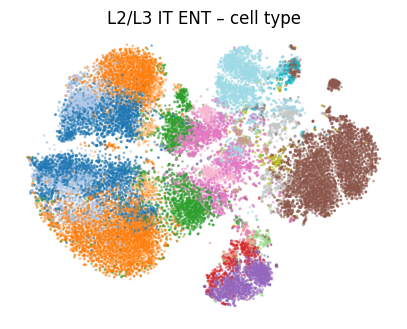

In [79]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

ax.scatter(*embd_ent_after_pca.T, s=1, c=cell_colors, alpha=0.4)
ax.set_title("L2/L3 IT ENT – cell type")
ax.axis("off")
ax.set_aspect("equal")

In [80]:
librarySizes = np.sum(yao['counts'][mask_L23_ent], axis=1)
# [:, importantGenesYao]
X = np.log1p(yao['counts'][mask_L23_ent] / librarySizes * 1e+6) # / np.log(2)  # is supposed to be log_2 (1+x)
print(X.shape)
X = X.toarray()
print(X.shape)
# X_mean = X.mean(axis=0)
# X = X - X_mean
U, s, V = np.linalg.svd(X-X.mean(axis=0), full_matrices=False)

U[:, np.sum(V, axis=1) < 0] *= -1
X = np.dot(U, np.diag(s))
x_subset_pre_pca = X[:, np.argsort(s)[::-1]][:, :50]

# #larger data.....
# # largedata = (cell_number, 3000)
# largedata = largedata - X_mean
# large_X = np.dot(largedata, V)[:, np.argsort(s)[::-1]] #????
# #larger data.....

(26588, 593)
(26588, 593)


In [82]:
# tsne of pre PCA subset
embedder_ent = TSNE(verbose=True)
embd_ent_before_pca = embedder_ent.fit(x_subset_pre_pca)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 11.28 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.93 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.01 seconds
===> Running optimization with exaggeration=12.00, lr=2215.67 for 250 iterations...
Iteration   50, KL divergence 5.3183, 50 iterations in 2.0537 sec
Iteration  100, KL divergence 5.3285, 50 iterations in 2.0662 sec
Iteration  150, KL divergence 5.3170, 50 iterations in 2.0572 sec
Iteration  200, KL divergence 5.3133, 50 iterations in 2.0474 sec
Iteration  250, KL divergence 5.3106, 50 iterations in 2.0601 sec
   --> Time elapsed: 10.29 seconds
===> Running optimization with exaggeration=1.00, lr=26588.00 for 500 

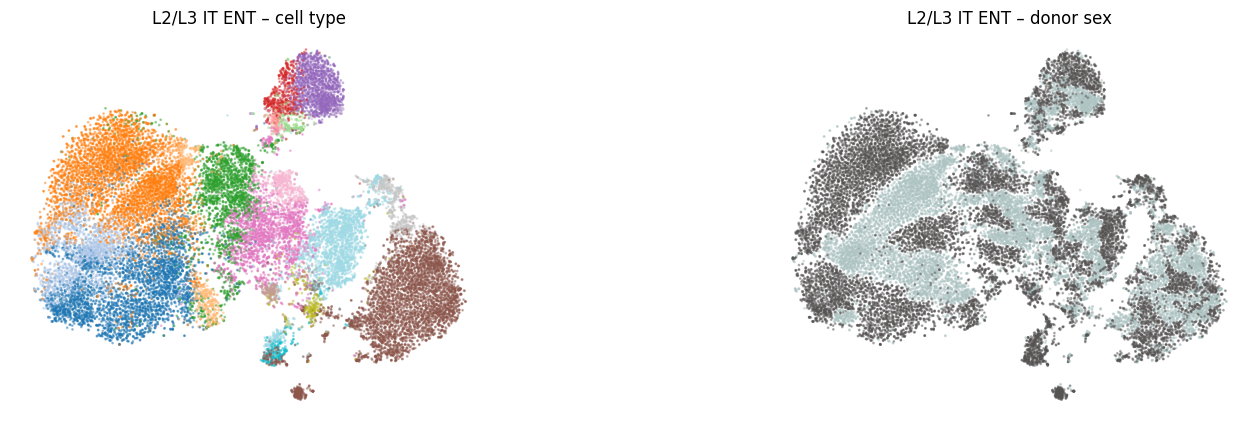

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))

ax[0].scatter(*embd_ent_before_pca.T, s=1, c=cell_colors, alpha=0.4)
ax[0].set_title("L2/L3 IT ENT – cell type")
ax[0].axis("off")
ax[0].set_aspect("equal")


ax[1].scatter(*embd_ent_before_pca.T, s=1, c=meta_ent["donor_sex_color"], alpha=0.4)
ax[1].set_title("L2/L3 IT ENT – donor sex")
ax[1].axis("off")
ax[1].set_aspect("equal")

In [ ]:
# subset before gene selection

In [84]:
mask_L23_ent.shape

(1169213,)

In [145]:
# load all genes but just for subsampled ent L23, then do all preproc on these cells only

In [94]:
mask_L23_ent.sum()

np.int64(26588)

In [128]:
start_full_load_time = time.time()
counts_ent, genes_ent, cells_ent = sparseload(file_name_10x,
                                                 chunksize = 2500,
                                                 yao = True,
                                                 row_positions=ind[mask_L23_ent])  #26588
# np.save(os.path.join(result_dir, "counts_full.npy"), counts_full)
# actually its quite good, tho only 367 genes are selected....... and 10 minutes in total.....
end_full_load_time = time.time()
print(f"counts are done. Time: {end_full_load_time - start_full_load_time}")
current_time = time.strftime("%H:%M:%S", time.localtime())

print(f"Preprocessing is done. Time: {current_time}")

.Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Sox17', 'Gm37323', 'Mrpl15',
       'Lypla1', 'Gm37988', 'Tcea1',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'AC149090.1', 'CAAA01118383.1', 'Vmn2r122',
       'CAAA01147332.1'],
      dtype='object', length=31053)
(2500, 31053)
.Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Sox17', 'Gm37323', 'Mrpl15',
       'Lypla1', 'Gm37988', 'Tcea1',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'AC149090.1', 'CAAA01118383.1', 'Vmn2r122',
       'CAAA01147332.1'],
      dtype='object', length=31053)
(2500, 31053)
.Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Sox17', 'Gm37323', 'Mrpl15',
       'Lypla1', 'Gm37988', 'Tcea1',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'AC149090.1', 'CAAA01118383.1', 'Vmn2r122',
       'CAAA01147332.1'],
      dtype='object', length=3

In [129]:
# reorder as in meta_ent
pos = {sample_name: i for i, sample_name in enumerate(cells_ent)}
idx = np.array([pos[sample_name] for sample_name in meta_ent["sample_name"]])

counts_ent = counts_ent[idx]
cells_ent = cells_ent[idx]

In [130]:
counts_ent.shape

(26588, 31053)

In [140]:
ent_L23 = {'counts': counts_ent, 'genes': genes_ent,'clusters': clusters, "samples_names": cells_ent,}

save_dict(yao, os.path.join(result_dir, "ent_L23.pkl"))

(1169320, 1)


Chosen offset: 0.00


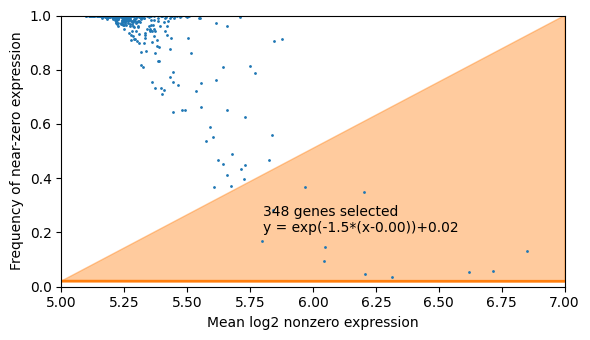

In [131]:
importantGenesEnt = geneSelection(counts_ent, n=3000, threshold=32)

In [132]:
importantGenesEnt.shape

(31053,)

In [148]:
genes_ent[importantGenesEnt]

array(['Sntg1', 'Kcnb2', 'Gm28153', 'Kcnq5', 'Rims1', 'Adgrb3', 'Tmeff2',
       'Map2', 'Erbb4', 'Igfbp5', 'Fbxo36', '2810459M11Rik', 'Pam',
       'Cntnap5b', 'Cntnap5a', 'Dpp10', 'Gm28928', 'R3hdm1', 'Brinp3',
       'Cacna1e', 'Atp1b1', 'Rgs4', 'Rgs7', 'Frmd4a', 'Celf2', 'C1ql3',
       'Etl4', 'Gpr158', 'Olfm1', '1110008P14Rik', 'Stxbp1', 'Strbp',
       'Lrp1b', 'Cacnb4', 'Kcnh7', 'Scn2a', 'Chn1', 'Pde1a', 'Lrrc4c',
       'Slc1a2', 'Bdnf', 'Ryr3', '1700020I14Rik', 'Plcb1', 'Snap25',
       'Macrod2', 'Pcsk2', 'Napb', 'Fkbp1a', '2900097C17Rik', 'Nnat',
       'Snhg11', 'Ptprt', 'Pkig', 'Ywhab', 'Syp', 'Pcsk1n', 'Tspan7',
       'Syn1', 'Gria3', 'Tenm1', 'Dmd', 'Il1rapl1', 'Xist', 'Il1rapl2',
       'Gpm6b', 'Tmsb4x', 'Stmn2', 'Ralyl', 'Nlgn1', 'Egfem1', 'Pex5l',
       'Dclk1', 'Nbea', 'Ppm1l', 'Gria2', 'Trim2', 'Syt11', 'Ntng1',
       'Plppr4', 'Camk2d', 'Ank2', 'Ppp3ca', 'Lmo4', 'St6galnac5',
       'Negr1', 'Lrrc7', 'Necab1', 'Lingo2', 'Brinp1', 'Ptprd', 'Slc24a2',
       'Pd

In [149]:
np.save(os.path.join(result_dir, "importantGenesEnt_mask.npy"), importantGenesEnt)
np.save(os.path.join(result_dir, "importantGenesEnt.npy"), genes_ent[importantGenesEnt])

In [133]:
counts_ent_filtered = counts_ent[:, importantGenesEnt]

In [134]:
librarySizes = np.sum(counts_ent_filtered, axis=1)
# [:, importantGenesYao]
X = np.log1p(counts_ent_filtered / librarySizes * 1e+6) # / np.log(2)  # is supposed to be log_2 (1+x)
print(X.shape)
X = X.toarray()
print(X.shape)
# X_mean = X.mean(axis=0)
# X = X - X_mean
U, s, V = np.linalg.svd(X-X.mean(axis=0), full_matrices=False)

U[:, np.sum(V, axis=1) < 0] *= -1
X = np.dot(U, np.diag(s))
x_subset_pre_gene = X[:, np.argsort(s)[::-1]][:, :50]

(26588, 348)
(26588, 348)


In [141]:
np.save(os.path.join(result_dir, "ent_L23_PCA50.npy"), x_subset_pre_gene)

In [ ]:
x_subset_pre_gene = np.load(os.path.join(result_dir, "ent_L23_PCA50.npy"))

In [135]:
# tsne of pre PCA subset
embedder_ent = TSNE(verbose=True)
embd_ent_pre_gene = embedder_ent.fit(x_subset_pre_gene)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 11.79 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.91 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.01 seconds
===> Running optimization with exaggeration=12.00, lr=2215.67 for 250 iterations...
Iteration   50, KL divergence 5.3785, 50 iterations in 2.0839 sec
Iteration  100, KL divergence 5.4101, 50 iterations in 2.0731 sec
Iteration  150, KL divergence 5.4098, 50 iterations in 2.0637 sec
Iteration  200, KL divergence 5.4086, 50 iterations in 2.0685 sec
Iteration  250, KL divergence 5.4085, 50 iterations in 2.0663 sec
   --> Time elapsed: 10.36 seconds
===> Running optimization with exaggeration=1.00, lr=26588.00 for 500 

In [139]:
meta_ent["cluster_label"]

0          151_L2 IT ENTl
1          151_L2 IT ENTl
2        157_L2/3 IT ENTl
3          151_L2 IT ENTl
4        157_L2/3 IT ENTl
               ...       
26583    155_L2/3 IT ENTl
26584    160_L2/3 IT ENTl
26585    161_L2/3 IT ENTl
26586    155_L2/3 IT ENTl
26587      138_L3 IT ENTm
Name: cluster_label, Length: 26588, dtype: object

In [136]:
cell_colors = meta_ent["cluster_label"].map(cluster_color_map).tolist()

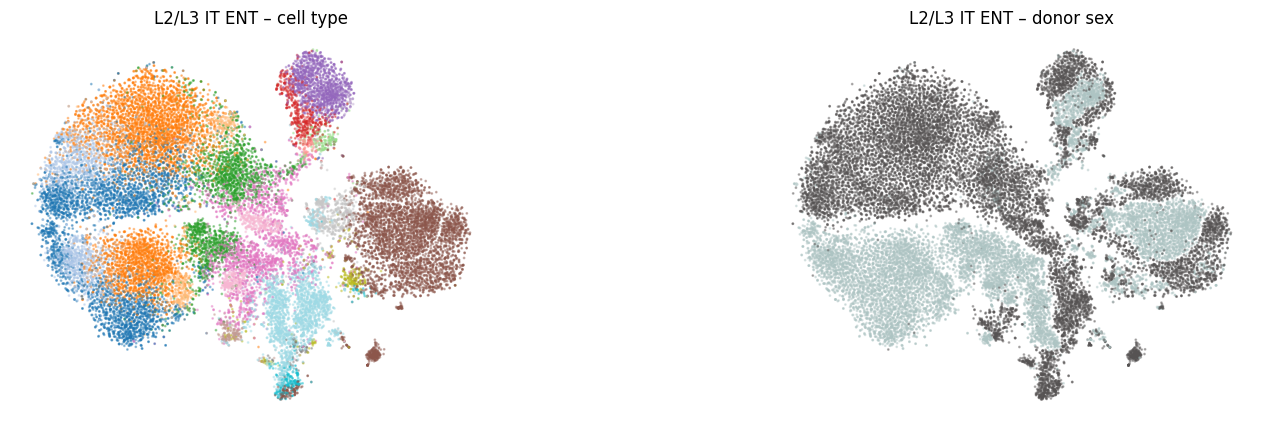

In [137]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))

ax[0].scatter(*embd_ent_pre_gene.T, s=1, c=cell_colors, alpha=0.4)
ax[0].set_title("L2/L3 IT ENT – cell type")
ax[0].axis("off")
ax[0].set_aspect("equal")


ax[1].scatter(*embd_ent_pre_gene.T, s=1, c=meta_ent["donor_sex_color"], alpha=0.4)
ax[1].set_title("L2/L3 IT ENT – donor sex")
ax[1].axis("off")
ax[1].set_aspect("equal")

In [144]:
np.all(cells_ent == meta_ent["sample_name"])

np.True_